In [12]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", category=FutureWarning)

print("Library berhasil diimpor.")

Library berhasil diimpor.


In [13]:
DATA_PATH = Path.cwd() / "faults.csv"

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset tidak ditemukan: {DATA_PATH.resolve()}\n"
        "Pastikan fault.csv berada satu folder dengan notebook."
    )

# Mencoba separator umum; file CSV standar akan terbaca pada percobaan pertama.
try:
    df = pd.read_csv(DATA_PATH)
    if df.shape[1] == 1:
        df_alt = pd.read_csv(DATA_PATH, sep=";")
        if df_alt.shape[1] > 1:
            df = df_alt
except Exception:
    df = pd.read_csv(DATA_PATH, sep=";")

df.columns = df.columns.astype(str).str.strip()
print("Lokasi dataset:", DATA_PATH.resolve())
print("Ukuran dataset:", df.shape)
display(df.head())

Lokasi dataset: C:\Users\Mutia\Downloads\The-Bujang-Kelompok-3-dev\faults.csv
Ukuran dataset: (1941, 34)


,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,...,Orientation_Index,Luminosity_Index,SigmoidOfAreas,Pastry,Z_Scratch,K_Scatch,Stains,Dirtiness,Bumps,Other_Faults
0,42,50,270900,270944,267,17,44,24220,76,108,...,0.8182,-0.2913,0.5822,1,0,0,0,0,0,0
1,645,651,2538079,2538108,108,10,30,11397,84,123,...,0.7931,-0.1756,0.2984,1,0,0,0,0,0,0
2,829,835,1553913,1553931,71,8,19,7972,99,125,...,0.6667,-0.1228,0.2150,1,0,0,0,0,0,0
3,853,860,369370,369415,176,13,45,18996,99,126,...,0.8444,-0.1568,0.5212,1,0,0,0,0,0,0
4,1289,1306,498078,498335,2409,60,260,246930,37,126,...,0.9338,-0.1992,1.0000,1,0,0,0,0,0,0


In [14]:
print("Nama kolom:")
print(df.columns.tolist())

Nama kolom:
['X_Minimum', 'X_Maximum', 'Y_Minimum', 'Y_Maximum', 'Pixels_Areas', 'X_Perimeter', 'Y_Perimeter', 'Sum_of_Luminosity', 'Minimum_of_Luminosity', 'Maximum_of_Luminosity', 'Length_of_Conveyer', 'TypeOfSteel_A300', 'TypeOfSteel_A400', 'Steel_Plate_Thickness', 'Edges_Index', 'Empty_Index', 'Square_Index', 'Outside_X_Index', 'Edges_X_Index', 'Edges_Y_Index', 'Outside_Global_Index', 'LogOfAreas', 'Log_X_Index', 'Log_Y_Index', 'Orientation_Index', 'Luminosity_Index', 'SigmoidOfAreas', 'Pastry', 'Z_Scratch', 'K_Scatch', 'Stains', 'Dirtiness', 'Bumps', 'Other_Faults']


In [15]:
# Kolom label/kelas pada dataset
TARGET_COLUMNS = [
    "Pastry",
    "Z_Scratch",
    "K_Scatch",
    "Stains",
    "Dirtiness",
    "Bumps",
    "Other_Faults"
]

# Pastikan semua kolom label tersedia
missing = [col for col in TARGET_COLUMNS if col not in df.columns]

if missing:
    raise ValueError(f"Kolom label tidak ditemukan: {missing}")

# Ambil fitur dan label
X = df.drop(columns=TARGET_COLUMNS).copy()

# Ubah 7 kolom label menjadi satu nama kelas
label_matrix = df[TARGET_COLUMNS]

# Setiap baris seharusnya memiliki tepat satu label bernilai 1
label_count = label_matrix.sum(axis=1)

if not label_count.eq(1).all():
    raise ValueError(
        "Ada baris yang tidak memiliki tepat satu label aktif. "
        "Periksa kolom label pada dataset."
    )

y = label_matrix.idxmax(axis=1)
y.name = "fault_type"

print("Shape fitur:", X.shape)
print("Jumlah data:", len(y))
print("\nDistribusi kelas:")
print(y.value_counts())

Shape fitur: (1941, 27)
Jumlah data: 1941

Distribusi kelas:
fault_type
Other_Faults    673
Bumps           402
K_Scatch        391
Z_Scratch       190
Pastry          158
Stains           72
Dirtiness        55
Name: count, dtype: int64


In [22]:
results = []

depth_values = [2, 3, 4, 5, 7, 10, 15, 20, 25, 30, None]

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

for depth in depth_values:
    model = RandomForestClassifier(
        n_estimators=200,
        max_depth=depth,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "f1_macro": "f1_macro"
        },
        return_train_score=True,
        n_jobs=-1
    )

    results.append({
        "max_depth": str(depth),
        "train_accuracy": scores["train_accuracy"].mean(),
        "cv_accuracy": scores["test_accuracy"].mean(),
        "cv_f1_macro": scores["test_f1_macro"].mean()
    })

depth_results = pd.DataFrame(results)

display(
    depth_results.sort_values(
        "cv_f1_macro",
        ascending=False
    ).reset_index(drop=True)
)

,max_depth,train_accuracy,cv_accuracy,cv_f1_macro
0,20,1.000000,0.775104,0.794892
1,15,0.998873,0.775110,0.793945
2,25,1.000000,0.773181,0.791615
3,None,1.000000,0.772536,0.791239
4,30,1.000000,0.772536,0.791239
5,10,0.947648,0.757710,0.788446
6,7,0.799612,0.710045,0.750383
7,5,0.693782,0.660431,0.703628
8,4,0.643687,0.615969,0.649676
9,3,0.568781,0.552163,0.569202


In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Data training:", X_train.shape)
print("Data testing:", X_test.shape)

Data training: (1552, 27)
Data testing: (389, 27)


,max_depth,train_accuracy,cv_accuracy,cv_f1_macro
0,20,1.000000,0.775104,0.794892
1,15,0.998873,0.775110,0.793945
2,25,1.000000,0.773181,0.791615
3,None,1.000000,0.772536,0.791239
4,30,1.000000,0.772536,0.791239
5,10,0.947648,0.757710,0.788446
6,7,0.799612,0.710045,0.750383
7,5,0.693782,0.660431,0.703628
8,4,0.643687,0.615969,0.649676
9,3,0.568781,0.552163,0.569202


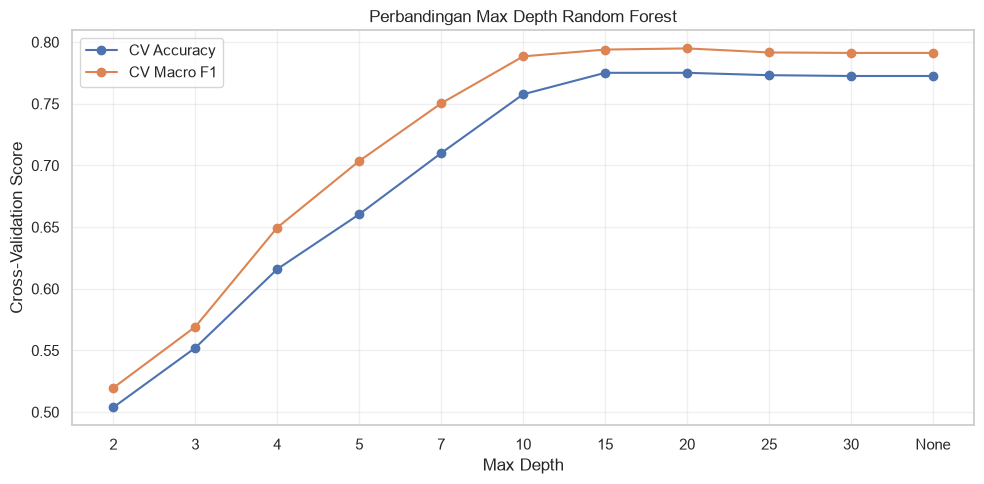

In [23]:
plot_df = depth_results.copy()

# Ubah max_depth menjadi angka untuk mengurutkan sumbu X
plot_df["depth_num"] = plot_df["max_depth"].map(
    lambda x: float("inf") if str(x) == "None" else float(x)
)

plot_df = plot_df.sort_values("depth_num")

# Buat label sumbu X
plot_df["depth_label"] = plot_df["max_depth"]

depth_results = pd.DataFrame(results)

display(
    depth_results.sort_values(
        "cv_f1_macro",
        ascending=False
    ).reset_index(drop=True)
)

plt.figure(figsize=(10, 5))

plt.plot(
    plot_df["depth_label"],
    plot_df["cv_accuracy"],
    marker="o",
    label="CV Accuracy"
)

plt.plot(
    plot_df["depth_label"],
    plot_df["cv_f1_macro"],
    marker="o",
    label="CV Macro F1"
)

plt.xlabel("Max Depth")
plt.ylabel("Cross-Validation Score")
plt.title("Perbandingan Max Depth Random Forest")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [24]:
best_row = depth_results.loc[
    depth_results["cv_f1_macro"].idxmax()
]

best_depth = (
    None if best_row["max_depth"] == "None"
    else int(best_row["max_depth"])
)

print("Max depth terbaik:", best_depth)
print("CV Macro F1:", round(best_row["cv_f1_macro"], 4))
print("CV Accuracy:", round(best_row["cv_accuracy"], 4))

Max depth terbaik: 20
CV Macro F1: 0.7949
CV Accuracy: 0.7751


Pada kode tersebut, `max_depth` dan `CV Macro F1` berperan penting dalam menentukan kedalaman pohon Decision Tree dan mengevaluasi seberapa baik model memprediksi jenis cacat pada Steel Plates Faults.

## 1. Pengaruh `max_depth`

`max_depth` adalah batas kedalaman maksimum pohon keputusan (Decision Tree). Parameter ini mengatur seberapa kompleks aturan yang dipelajari model dari data training.

- `max_depth` kecil: pohon lebih sederhana, proses pelatihan lebih cepat, tetapi bisa mengalami underfitting karena pola data belum dipelajari dengan cukup baik.
- `max_depth` besar: pohon bisa mempelajari pola yang lebih kompleks, tetapi berisiko mengalami overfitting, yaitu terlalu menyesuaikan diri dengan data training.
- `max_depth=None`: pohon tumbuh tanpa batas kedalaman yang ditentukan secara eksplisit, sampai kondisi penghentian lainnya terpenuhi.

Dalam hasil yang kamu tunjukkan, nilai terbaik adalah:

```
best_depth = 20
```

Artinya, berdasarkan hasil evaluasi yang tersimpan di `depth_results`, kedalaman maksimum 20 menghasilkan nilai `cv_f1_macro` tertinggi dibandingkan pilihan kedalaman lain yang diuji. Ini tidak berarti kedalaman 20 selalu menjadi yang terbaik untuk semua dataset atau semua pembagian data.

## 2. Pengaruh `CV Macro F1`

`CV Macro F1` adalah nilai rata-rata Macro F1-score dari proses Cross-Validation (CV).

Cross-validation membagi data training menjadi beberapa bagian (fold). Model dilatih dan divalidasi secara bergantian pada bagian-bagian tersebut, kemudian skor dirata-ratakan.

Macro F1 menghitung F1-score untuk setiap kelas secara terpisah, lalu mengambil rata-rata dengan bobot yang sama. Pada dataset ini, kelasnya adalah `Pastry`, `Z_Scratch`, `K_Scatch`, `Stains`, `Dirtiness`, `Bumps`, dan `Other_Faults`.

Nilai pada hasilmu:

- CV Macro F1 = 0.7949, atau sekitar 79,49%.
- CV Accuracy = 0.7751, atau sekitar 77,51%.

Macro F1 sebesar 0,7949 menunjukkan bahwa rata-rata F1-score antar kelas cukup baik dalam pengujian cross-validation. Metrik ini berguna ketika jumlah data tiap kelas berbeda, karena setiap kelas memiliki bobot yang sama dalam rata-rata.

Namun, nilai Macro F1 bukan berarti tepat 79,49% dari seluruh prediksi benar. Untuk proporsi prediksi yang benar, lihat Accuracy.

## 3. Penjelasan kode yang kamu gunakan

```
best_row = depth_results.loc[    depth_results["cv_f1_macro"].idxmax()]best_depth = (    None if best_row["max_depth"] == "None"    else int(best_row["max_depth"]))print("Max depth terbaik:", best_depth)print("CV Macro F1:", round(best_row["cv_f1_macro"], 4))print("CV Accuracy:", round(best_row["cv_accuracy"], 4))
```

Penjelasan setiap bagian:

1. `idxmax()` mencari indeks baris dengan nilai `cv_f1_macro` tertinggi.
2. `depth_results.loc[...]` mengambil baris hasil pengujian yang memiliki skor tertinggi tersebut.
3. `best_depth` mengambil nilai `max_depth` dari baris terbaik. Jika nilainya berupa teks `"None"`, kode mengubahnya menjadi nilai Python `None`; jika bukan, nilainya diubah menjadi integer.
4. `round(..., 4)` membulatkan hasil metrik menjadi empat angka di belakang koma.

## 4. Hubungan keduanya

Hasil pengujianmu

Max depth terbaik

## 20

CV Macro F1

## 0.7949

Macro F1

79,49%

CV Accuracy

## 0.7751

Accuracy

77,51%

`max_depth` menentukan kompleksitas model, sedangkan `CV Macro F1` membantu menilai kualitas model pada beberapa pembagian data. Dalam kode ini, kedalaman 20 dipilih karena menghasilkan CV Macro F1 tertinggi di antara kandidat yang diuji.

Catatan: hasil cross-validation digunakan untuk memilih parameter. Setelah itu, model sebaiknya tetap dievaluasi pada data testing yang terpisah agar performanya pada data yang belum pernah dilihat dapat dinilai secara lebih objektif.

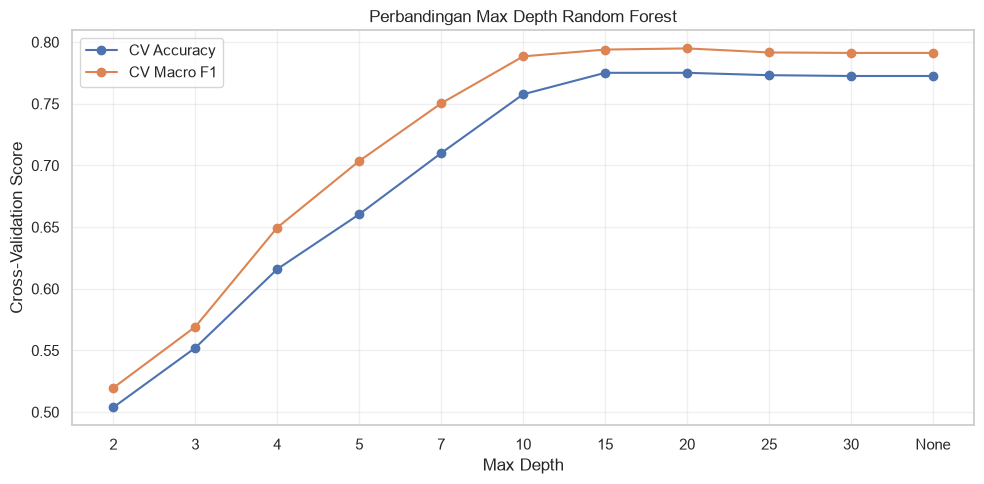

In [25]:
plot_df = depth_results.copy()

# Ubah max_depth menjadi angka untuk mengurutkan sumbu X
plot_df["depth_num"] = plot_df["max_depth"].map(
    lambda x: float("inf") if str(x) == "None" else float(x)
)

plot_df = plot_df.sort_values("depth_num")

# Buat label sumbu X
plot_df["depth_label"] = plot_df["max_depth"]

plt.figure(figsize=(10, 5))

plt.plot(
    plot_df["depth_label"],
    plot_df["cv_accuracy"],
    marker="o",
    label="CV Accuracy"
)

plt.plot(
    plot_df["depth_label"],
    plot_df["cv_f1_macro"],
    marker="o",
    label="CV Macro F1"
)

plt.xlabel("Max Depth")
plt.ylabel("Cross-Validation Score")
plt.title("Perbandingan Max Depth Random Forest")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

menghitung class imabalance

In [26]:
# Hitung jumlah sampel setiap kelas
class_counts = y.value_counts()

# Hitung persentase setiap kelas
class_percentages = (
    y.value_counts(normalize=True) * 100
).round(2)

imbalance_table = pd.DataFrame({
    "Jumlah Sampel": class_counts,
    "Persentase (%)": class_percentages
})

display(imbalance_table)

,Jumlah Sampel,Persentase (%)
fault_type,,
Other_Faults,673,34.67
Bumps,402,20.71
K_Scatch,391,20.14
Z_Scratch,190,9.79
Pastry,158,8.14
Stains,72,3.71
Dirtiness,55,2.83


karena distribusi kelas tidak seimbang, macro F1-score sangat berguna untuk proyekmu. Metrik ini menghitung F1 setiap kelas secara setara, sehingga performa buruk pada kelas minoritas tidak mudah tertutupi oleh performa kelas mayoritas.

In [27]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix
)

In [28]:
# Model 1: Tanpa penanganan class imbalance
rf_normal = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    class_weight=None,
    random_state=42,
    n_jobs=-1
)

# Model 2: Dengan penanganan class imbalance
rf_balanced = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Training kedua model
rf_normal.fit(X_train, y_train)
rf_balanced.fit(X_train, y_train)

# Prediksi data test
y_pred_normal = rf_normal.predict(X_test)
y_pred_balanced = rf_balanced.predict(X_test)

print("Kedua model berhasil dilatih.")

Kedua model berhasil dilatih.


In [29]:
results_comparison = pd.DataFrame([
    {
        "Model": "Random Forest - Normal",
        "Accuracy": accuracy_score(y_test, y_pred_normal),
        "Precision (Macro)": precision_score(
            y_test, y_pred_normal,
            average="macro", zero_division=0
        ),
        "Recall (Macro)": recall_score(
            y_test, y_pred_normal,
            average="macro", zero_division=0
        ),
        "F1-Score (Macro)": f1_score(
            y_test, y_pred_normal,
            average="macro", zero_division=0
        )
    },
    {
        "Model": "Random Forest - Balanced",
        "Accuracy": accuracy_score(y_test, y_pred_balanced),
        "Precision (Macro)": precision_score(
            y_test, y_pred_balanced,
            average="macro", zero_division=0
        ),
        "Recall (Macro)": recall_score(
            y_test, y_pred_balanced,
            average="macro", zero_division=0
        ),
        "F1-Score (Macro)": f1_score(
            y_test, y_pred_balanced,
            average="macro", zero_division=0
        )
    }
])

display(
    results_comparison
    .set_index("Model")
    .round(4)
)

,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro)
Model,,,,
Random Forest - Normal,0.8046,0.8576,0.7878,0.8182
Random Forest - Balanced,0.8021,0.8645,0.7897,0.8213
